Дополнительное задание
1. Выберите датасет для MLPClassifier, снимите метрики качества классификации, сравните результаты классификации с классичесикими моделями машинного обучения
2. Проверьте, удовлетворяет ли уравнению функция и где именно
* №1 $ u(x, t) = sin(x) + sint(t) $
* №2 $ u(x, t) = x * sint(t) $
* №3 $ u(x, t) = tanh(x * t + x) * sin(3 * t) $

In [20]:
import pandas as pd


data_url = 'D:\\MIREA\\DPO\\Learning\\Practic1_9\\mushrooms.csv'
data = pd.read_csv(data_url)
data

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [21]:
data.shape

(8124, 23)

Надо создать несколько датасетов под каждый из алгоритмов:
1. Catboost: можно и так кидать
2. RandomForest: обязательно буквенные параметры сделать категориальными или числовыми (LabelEncoding либо OrdinalEncoder)
3. MLPClassifier: обязательно буквенные параметры на столбцы разделить (OneHotEncoder)

In [22]:
from catboost import CatBoostClassifier
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score


grid = {}
y = LabelEncoder().fit_transform(data['class'])
X = data.drop(columns=['class', 'odor'])
# ----------------------------------------------------------------------
model_catboost = CatBoostClassifier(iterations=10, learning_rate=1,
                           depth=10, loss_function='Logloss',
                           verbose=0)
grid['Catboost'] = [model_catboost, X]

# ----------------------------------------------------------------------
model_randforest = RandomForestClassifier(max_depth=10)
data_randforest = OrdinalEncoder().fit_transform(X)
grid['Random Forest'] = [model_randforest, data_randforest] 

# ----------------------------------------------------------------------
model_mlp  = MLPClassifier(random_state=1, hidden_layer_sizes=(10, 10))
data_mlp = pd.get_dummies(X, drop_first=True)
grid['MLPCalssifier'] = [model_mlp, data_mlp]

# ----------------------------------------------------------------------
for name, [model, data_get] in grid.items():
    X_train, X_test, y_train, y_test = train_test_split(data_get, y, test_size=.05, random_state=42)
    if name == 'Catboost':
        model.fit(X_train, y_train, cat_features=list(range(data_get.shape[1])))
    else:
        model.fit(X_train, y_train)
    y_predict = model.predict(X_test)
    print(name)
    print('Accuracy: ', accuracy_score(y_test, y_predict))
    print('Precision: ', precision_score(y_test, y_predict))
    print('F1: ', f1_score(y_test, y_predict))


Catboost
Accuracy:  1.0
Precision:  1.0
F1:  1.0
Random Forest
Accuracy:  1.0
Precision:  1.0
F1:  1.0
MLPCalssifier
Accuracy:  1.0
Precision:  1.0
F1:  1.0


Слишком простой датасет

In [23]:
data = pd.read_csv('D:\\MIREA\\DPO\\Learning\\Practic1_9\\adult.csv')
data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [24]:
data.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [25]:
model = CatBoostClassifier(iterations=10, loss_function='MultiClass')
y = data['income']
X = data.drop(columns=['income'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.5)
model.fit(X_train, y_train, cat_features=[1, 3, 5, 6, 7, 8, 9, 13])
y_predict = model.predict(X_test)
accuracy_score(y_test, y_predict)

Learning rate set to 0.5
0:	learn: 0.4806769	total: 29.5ms	remaining: 265ms
1:	learn: 0.4021935	total: 60.8ms	remaining: 243ms
2:	learn: 0.3638676	total: 92.6ms	remaining: 216ms
3:	learn: 0.3411031	total: 125ms	remaining: 188ms
4:	learn: 0.3256269	total: 157ms	remaining: 157ms
5:	learn: 0.3181558	total: 186ms	remaining: 124ms
6:	learn: 0.3132903	total: 220ms	remaining: 94.1ms
7:	learn: 0.3077938	total: 253ms	remaining: 63.2ms
8:	learn: 0.3053690	total: 283ms	remaining: 31.4ms
9:	learn: 0.3026820	total: 311ms	remaining: 0us


0.8612259940215389

In [26]:
for i in data.columns:
    print(data[i].value_counts())

age
36    1348
35    1337
33    1335
23    1329
31    1325
      ... 
88       6
85       5
87       3
89       2
86       1
Name: count, Length: 74, dtype: int64
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64
fnlwgt
203488    21
120277    19
190290    19
125892    18
126569    18
          ..
345898     1
252208     1
129912     1
255835     1
257302     1
Name: count, Length: 28523, dtype: int64
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, d

In [27]:
import numpy as np


data = data.replace(r'\s*\?\s*', np.nan, regex=True)
for column in data.columns:
    print(data[column].isna().value_counts())

age
False    48842
Name: count, dtype: int64
workclass
False    46043
True      2799
Name: count, dtype: int64
fnlwgt
False    48842
Name: count, dtype: int64
education
False    48842
Name: count, dtype: int64
educational-num
False    48842
Name: count, dtype: int64
marital-status
False    48842
Name: count, dtype: int64
occupation
False    46033
True      2809
Name: count, dtype: int64
relationship
False    48842
Name: count, dtype: int64
race
False    48842
Name: count, dtype: int64
gender
False    48842
Name: count, dtype: int64
capital-gain
False    48842
Name: count, dtype: int64
capital-loss
False    48842
Name: count, dtype: int64
hours-per-week
False    48842
Name: count, dtype: int64
native-country
False    47985
True       857
Name: count, dtype: int64
income
False    48842
Name: count, dtype: int64


Пропуски в native-country, occupation и workclass

In [28]:
data['native-country'] = data['native-country'].fillna(data['native-country'].mode())
data['occupation'] = data['occupation'].fillna(data['occupation'].mode())
data['workclass'] = data['workclass'].fillna(data['workclass'].mode())

In [29]:
data = data.drop(columns=['fnlwgt'])
data

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


Хммм, у нас же обучение должно зависеть от количества часов обучения?

In [30]:
import seaborn as sns
from scipy.stats.contingency import association

ct = pd.crosstab(data['education'], data['educational-num'])

# Вычисляем коэффициент Крамера
cramer_v = association(ct, method="cramer")
print(f"Коэффициент Крамера: {cramer_v}")

Коэффициент Крамера: 1.0


Значит оставим только education

Теперь проверим свадебный статус

In [31]:
ct = pd.crosstab(data['marital-status'], data['relationship'])

cramer_v = association(ct, method='cramer')
print('Коэффициент крамера: ', cramer_v)

Коэффициент крамера:  0.48815980396007874


Не очень коррелирует, но можон заметить, что заключение брака сильно влияет на доход

<function matplotlib.pyplot.show(close=None, block=None)>

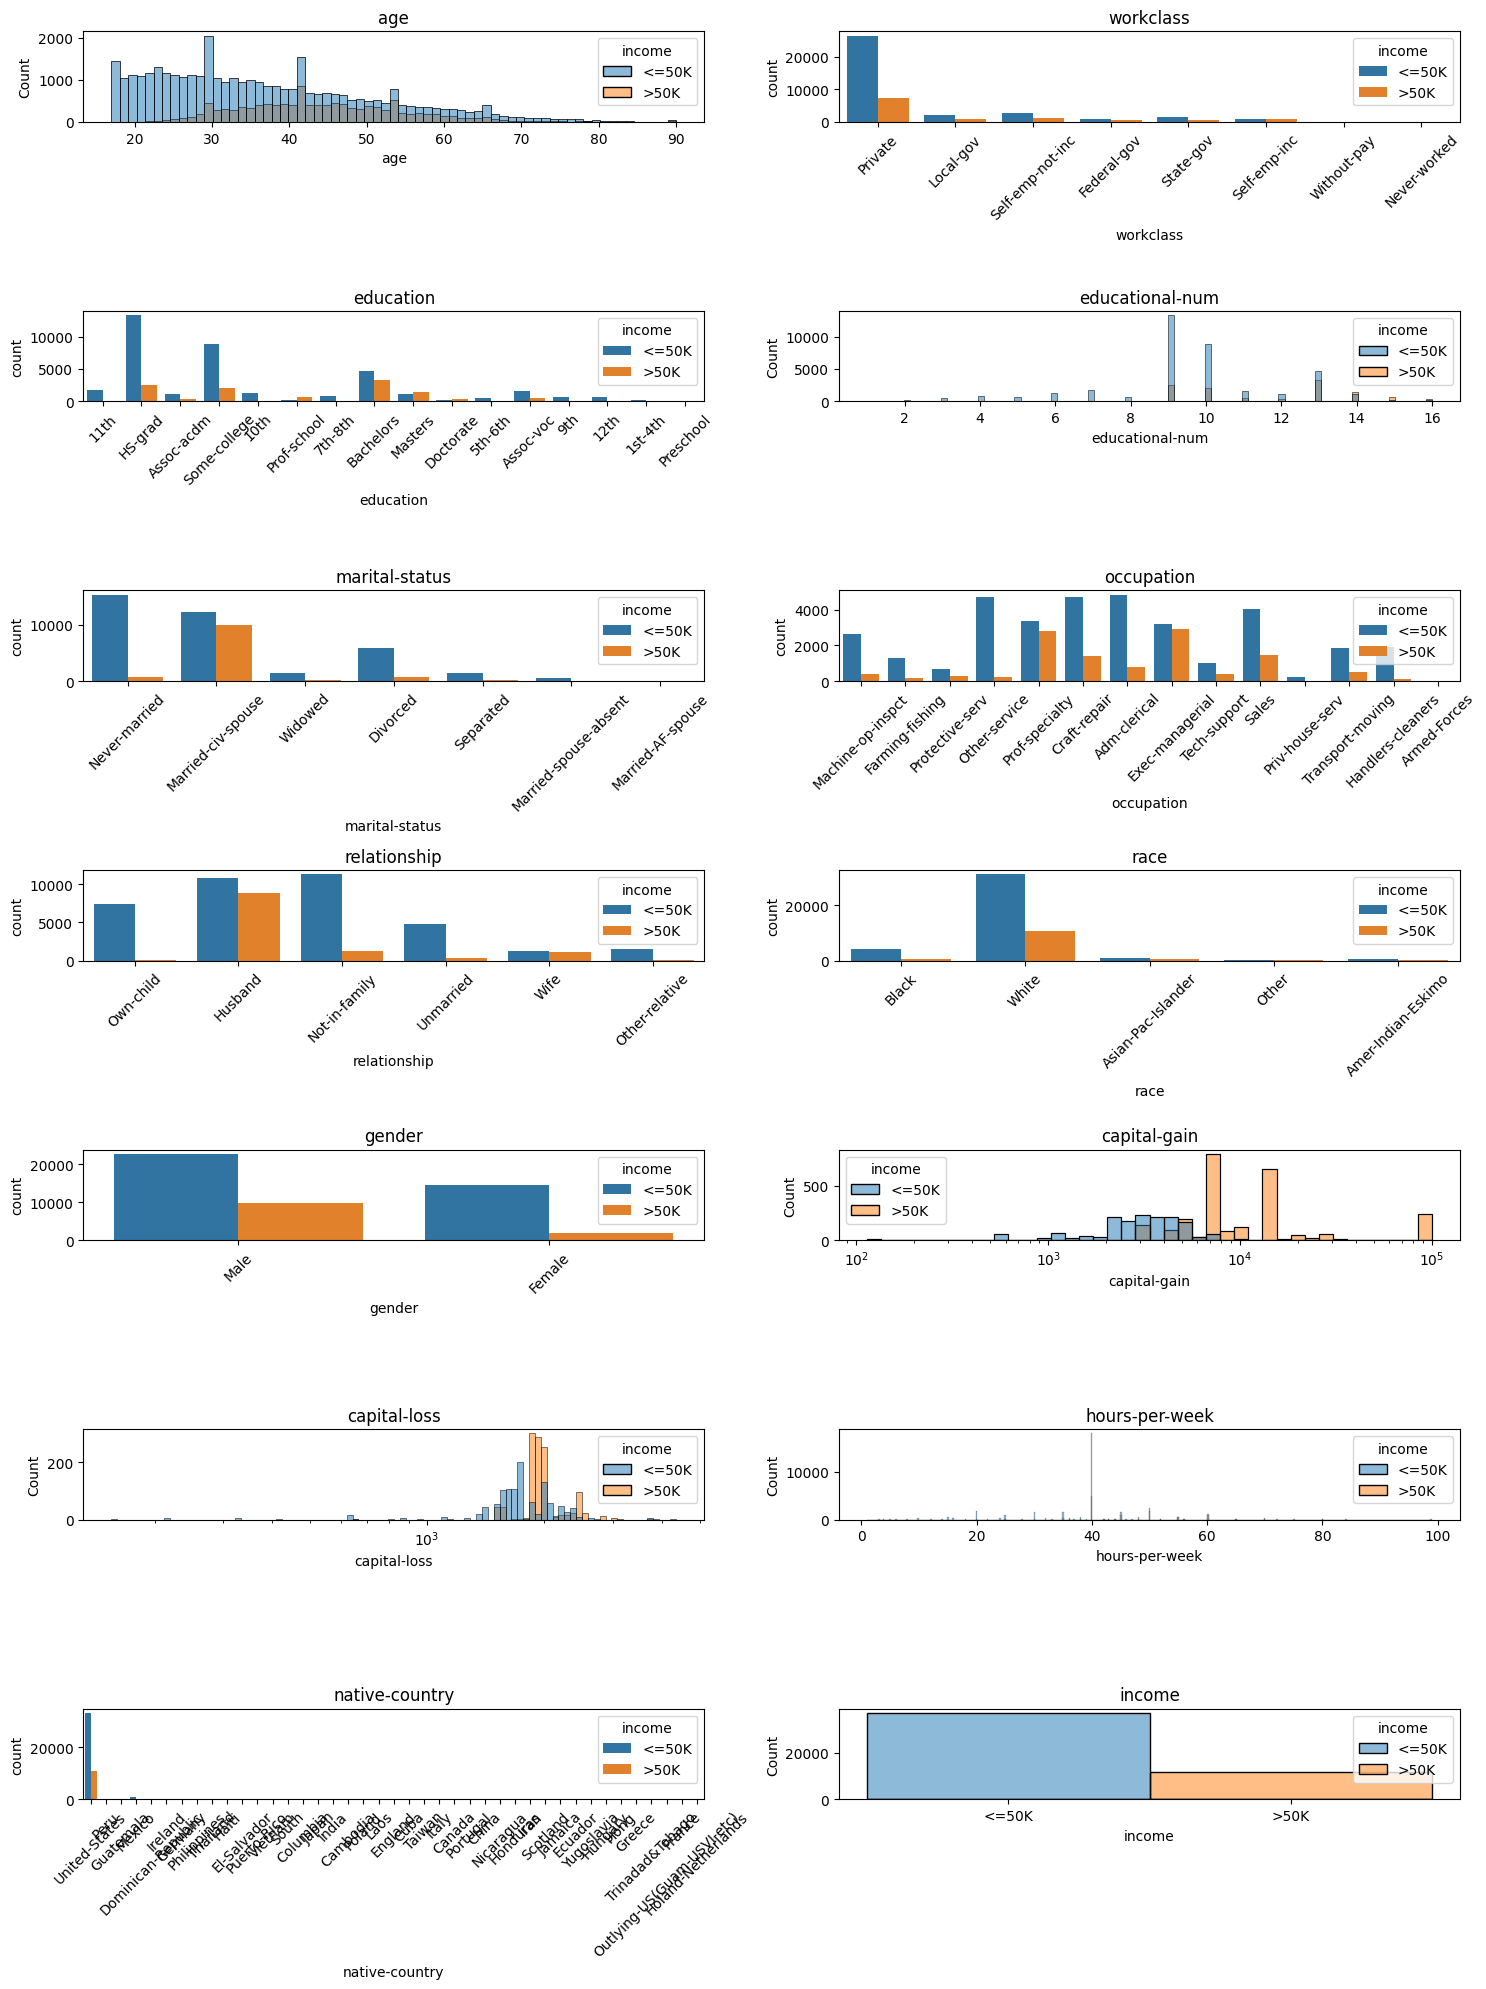

In [32]:
import matplotlib.pyplot as plt


ln = 15
cat_labels = [1, 2, 4, 5, 6, 7, 8, 12]
y = 'income'
fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(15, 20))

ax_flatten = axes.flatten()

for i, ax in enumerate(ax_flatten):
    column = data.columns[i]
    if i in cat_labels:
        sns.countplot(data=data, x=column, hue=y, ax=ax)
        ax.tick_params(axis='x', rotation=45)
    elif column in ['capital-gain', 'capital-loss']:
        sns.histplot(data=data, x=column, hue=y, ax=ax, log_scale=True)
    else:
        sns.histplot(data=data, x=column, hue=y, ax=ax)
    ax.set_title(column)


plt.tight_layout(w_pad=1)
plt.show

In [33]:
data['IsMarried'] = np.where(data['marital-status'] == 'Married-civ-spouse', 1, 0)
data_copy = data.copy()
data = data.drop(columns=['marital-status', 'relationship'])
data

,age,workclass,education,educational-num,occupation,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,IsMarried
0,25,Private,11th,7,Machine-op-inspct,Black,Male,0,0,40,United-States,<=50K,0
1,38,Private,HS-grad,9,Farming-fishing,White,Male,0,0,50,United-States,<=50K,1
2,28,Local-gov,Assoc-acdm,12,Protective-serv,White,Male,0,0,40,United-States,>50K,1
3,44,Private,Some-college,10,Machine-op-inspct,Black,Male,7688,0,40,United-States,>50K,1
4,18,NaN,Some-college,10,NaN,White,Female,0,0,30,United-States,<=50K,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,Assoc-acdm,12,Tech-support,White,Female,0,0,38,United-States,<=50K,1
48838,40,Private,HS-grad,9,Machine-op-inspct,White,Male,0,0,40,United-States,>50K,1
48839,58,Private,HS-grad,9,Adm-clerical,White,Female,0,0,40,United-States,<=50K,0
48840,22,Private,HS-grad,9,Adm-clerical,White,Male,0,0,20,United-States,<=50K,0


In [34]:
data['gender'] = data['gender'].map({'Male': 1, 'Female': 0})

   native-country income  percentage
0        Cambodia  <=50K    0.678571
1        Cambodia   >50K    0.321429
2          Canada  <=50K    0.653846
3          Canada   >50K    0.346154
4           China  <=50K    0.704918
..            ...    ...         ...
76  United-States   >50K    0.243977
77        Vietnam  <=50K    0.918605
78        Vietnam   >50K    0.081395
79     Yugoslavia  <=50K    0.652174
80     Yugoslavia   >50K    0.347826

[81 rows x 3 columns]


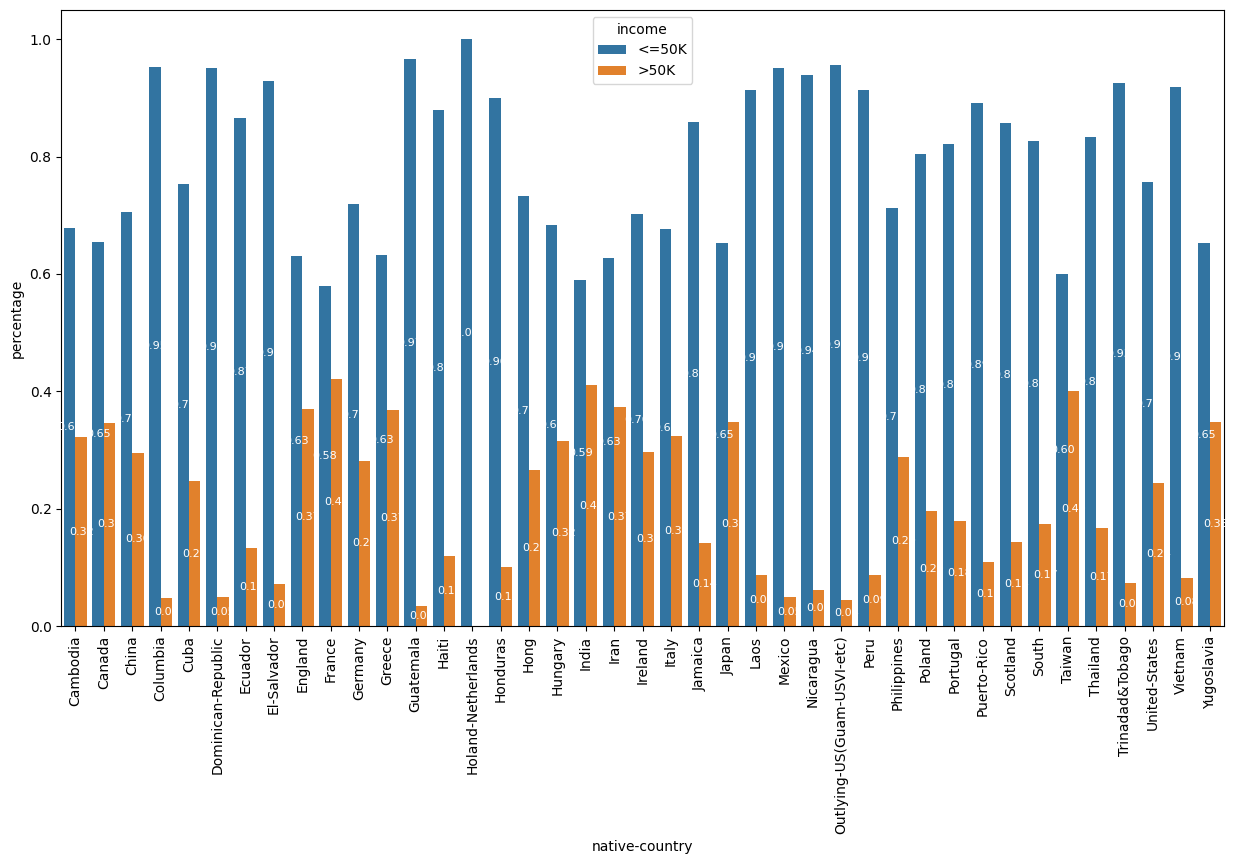

In [35]:
view_data = data.groupby('native-country')['income'].value_counts(normalize=True).reset_index(name='percentage')
print(view_data)
fig, ax = plt.subplots(figsize=(15, 8))
sns.barplot(data=view_data, x='native-country', y='percentage', hue='income', ax=ax, )

plt.xticks(rotation=90)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='center', color='white', fontsize=8)


In [36]:
data.groupby('native-country')['income'].value_counts()

native-country  income
Cambodia        <=50K        19
                >50K          9
Canada          <=50K       119
                >50K         63
China           <=50K        86
                          ...  
United-States   >50K      10694
Vietnam         <=50K        79
                >50K          7
Yugoslavia      <=50K        15
                >50K          8
Name: count, Length: 81, dtype: int64

In [37]:
rich_countries = [
    'United-States', 'Canada', 'England', 'Germany', 'Japan', 
    'France', 'Italy', 'Holand-Netherlands', 'Ireland', 'Taiwan',
    'Iran', 'India'
]

data['from_rich_country'] = data['native-country'].apply(lambda x: 1 if x in rich_countries else 0)
data = data.drop(columns='native-country')
data

,age,workclass,education,educational-num,occupation,race,gender,capital-gain,capital-loss,hours-per-week,income,IsMarried,from_rich_country
0,25,Private,11th,7,Machine-op-inspct,Black,1,0,0,40,<=50K,0,1
1,38,Private,HS-grad,9,Farming-fishing,White,1,0,0,50,<=50K,1,1
2,28,Local-gov,Assoc-acdm,12,Protective-serv,White,1,0,0,40,>50K,1,1
3,44,Private,Some-college,10,Machine-op-inspct,Black,1,7688,0,40,>50K,1,1
4,18,NaN,Some-college,10,NaN,White,0,0,0,30,<=50K,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,Assoc-acdm,12,Tech-support,White,0,0,0,38,<=50K,1,1
48838,40,Private,HS-grad,9,Machine-op-inspct,White,1,0,0,40,>50K,1,1
48839,58,Private,HS-grad,9,Adm-clerical,White,0,0,0,40,<=50K,0,1
48840,22,Private,HS-grad,9,Adm-clerical,White,1,0,0,20,<=50K,0,1


In [43]:
pd.concat([data.groupby('race')['income'].value_counts(), data.groupby('race')['income'].value_counts(normalize=True)], axis=1)

count  proportion
race               income                   
Amer-Indian-Eskimo <=50K     415    0.882979
                   >50K       55    0.117021
Asian-Pac-Islander <=50K    1110    0.730744
                   >50K      409    0.269256
Black              <=50K    4119    0.879189
                   >50K      566    0.120811
Other              <=50K     356    0.876847
                   >50K       50    0.123153
White              <=50K   31155    0.746013
                   >50K    10607    0.253987

Видно, что если у человека раса White или Asian-Pac-Islander, то у него на 10% шансов больше стать богатым, сделаем бинарный класс на основе этого

In [48]:
richRace = ['White', 'Asian-Pac-Islander	']
data['race'] = data['race'].apply(lambda x: 1 if x in richRace else 0)
data

,age,workclass,education,educational-num,occupation,race,gender,capital-gain,capital-loss,hours-per-week,income,IsMarried,from_rich_country
0,25,Private,11th,7,Machine-op-inspct,0,1,0,0,40,<=50K,0,1
1,38,Private,HS-grad,9,Farming-fishing,1,1,0,0,50,<=50K,1,1
2,28,Local-gov,Assoc-acdm,12,Protective-serv,1,1,0,0,40,>50K,1,1
3,44,Private,Some-college,10,Machine-op-inspct,0,1,7688,0,40,>50K,1,1
4,18,NaN,Some-college,10,NaN,1,0,0,0,30,<=50K,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,Assoc-acdm,12,Tech-support,1,0,0,0,38,<=50K,1,1
48838,40,Private,HS-grad,9,Machine-op-inspct,1,1,0,0,40,>50K,1,1
48839,58,Private,HS-grad,9,Adm-clerical,1,0,0,0,40,<=50K,0,1
48840,22,Private,HS-grad,9,Adm-clerical,1,1,0,0,20,<=50K,0,1


In [51]:
pd.concat([data.groupby('workclass')['income'].value_counts(), data.groupby('workclass')['income'].value_counts(normalize=True)], axis=1)

count  proportion
workclass        income                   
Federal-gov      <=50K     871    0.608240
                 >50K      561    0.391760
Local-gov        <=50K    2209    0.704401
                 >50K      927    0.295599
Never-worked     <=50K      10    1.000000
Private          <=50K   26519    0.782133
                 >50K     7387    0.217867
Self-emp-inc     >50K      938    0.553392
                 <=50K     757    0.446608
Self-emp-not-inc <=50K    2785    0.721129
                 >50K     1077    0.278871
State-gov        <=50K    1451    0.732458
                 >50K      530    0.267542
Without-pay      <=50K      19    0.904762
                 >50K        2    0.095238

In [52]:
data

,age,workclass,education,educational-num,occupation,race,gender,capital-gain,capital-loss,hours-per-week,income,IsMarried,from_rich_country
0,25,Private,11th,7,Machine-op-inspct,0,1,0,0,40,<=50K,0,1
1,38,Private,HS-grad,9,Farming-fishing,1,1,0,0,50,<=50K,1,1
2,28,Local-gov,Assoc-acdm,12,Protective-serv,1,1,0,0,40,>50K,1,1
3,44,Private,Some-college,10,Machine-op-inspct,0,1,7688,0,40,>50K,1,1
4,18,NaN,Some-college,10,NaN,1,0,0,0,30,<=50K,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,Assoc-acdm,12,Tech-support,1,0,0,0,38,<=50K,1,1
48838,40,Private,HS-grad,9,Machine-op-inspct,1,1,0,0,40,>50K,1,1
48839,58,Private,HS-grad,9,Adm-clerical,1,0,0,0,40,<=50K,0,1
48840,22,Private,HS-grad,9,Adm-clerical,1,1,0,0,20,<=50K,0,1


In [54]:
pd.concat([data.groupby('occupation')['income'].value_counts(), data.groupby('occupation')['income'].value_counts(normalize=True)], axis=1)

count  proportion
occupation        income                   
Adm-clerical      <=50K    4843    0.863126
                  >50K      768    0.136874
Armed-Forces      <=50K      10    0.666667
                  >50K        5    0.333333
Craft-repair      <=50K    4729    0.773724
                  >50K     1383    0.226276
Exec-managerial   <=50K    3178    0.522182
                  >50K     2908    0.477818
Farming-fishing   <=50K    1317    0.883893
                  >50K      173    0.116107
Handlers-cleaners <=50K    1934    0.933398
                  >50K      138    0.066602
Machine-op-inspct <=50K    2650    0.876903
                  >50K      372    0.123097
Other-service     <=50K    4719    0.958562
                  >50K      204    0.041438
Priv-house-serv   <=50K     239    0.987603
                  >50K        3    0.012397
Prof-specialty    <=50K    3388    0.548931
                  >50K     2784    0.451069
Protective-serv   <=50K     675    0.686673
                  >50K      308    0.313327
Sales             <=50K    4029    0.732013
                  >50K     1475    0.267987
Tech-support      <=50K    1026    0.709544
                  >50K      420    0.290456
Transport-moving  <=50K    1874    0.795754
                  >50K      481    0.204246